In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sim_functions import *

from tqdm import tqdm

from scipy.optimize import curve_fit

Using cupy


In [3]:
f_result = np.load("f_simulation_tube_flow_new.npy")
f_result = np.load("frame_output_mask2/f_sample_simulation.npy")
c_top = np.array([0.979, 0.000047, 0.0204, 1e-4])

(4, 9, 800, 400)
(4, 800, 400)
1275.7053395587616


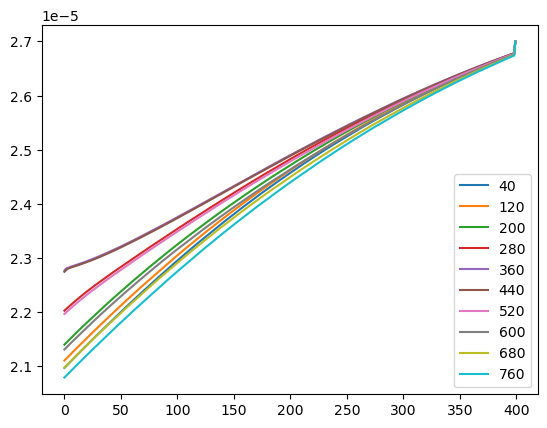

In [12]:
print(f_result.shape)
nx = f_result.shape[2]
rho_s = xp.sum(f_result, axis = 1, dtype = DTYPE)/3
#rho_s[-1, :, :] -= c_top[-1]
print(rho_s.shape)
for i in range(10):
    plt.plot(rho_s[1, i*(nx//10)+nx//20, :], label = f'{i*(nx//10)+nx//20}')
plt.legend()

slope = (rho_s[1, nx//2, 5]-rho_s[1, nx//2, 0])/5
b1_measured = rho_s[1, 50, 0]/slope
print(b1_measured)

In [13]:
L_grid = 0.5
L_gap = int(20//L_grid)
L_mask1 = int(3//L_grid)
L_mask2 = int(3//L_grid)
L_mask_side = int(40//L_grid-3*(L_mask1+L_mask2))

non_absorb_mask = xp.zeros(nx)
non_absorb_mask[nx//2+L_gap//2 : nx//2+L_gap//2+L_mask1] = True
non_absorb_mask[nx//2+L_gap//2+L_mask1+L_mask2 : nx//2+L_gap//2+2*L_mask1+L_mask2] = True
non_absorb_mask[nx//2+L_gap//2+2*L_mask1+2*L_mask2 : nx//2+L_gap//2+3*L_mask1+2*L_mask2] = True
non_absorb_mask[nx//2+L_gap//2+3*L_mask1+3*L_mask2 : nx//2+L_gap//2+3*L_mask1+3*L_mask2+L_mask_side] = True

non_absorb_mask[0: nx//2] = non_absorb_mask[nx//2:][::-1]

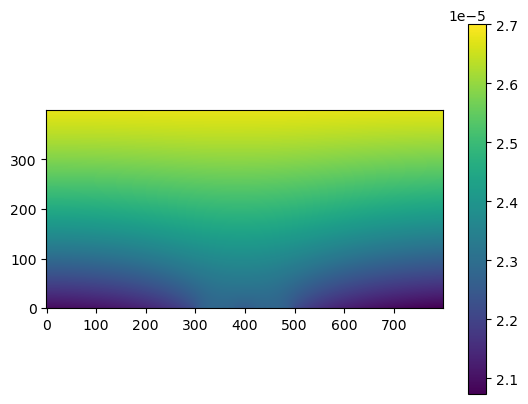

In [14]:
plt.imshow(rho_s[1, :, :].T, origin = 'lower')
plt.colorbar()

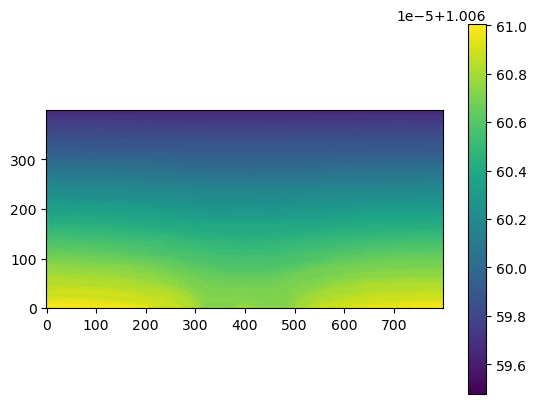

In [15]:
plt.imshow(np.sum(rho_s[:, :, :], axis = 0).T, origin = 'lower')
plt.colorbar()

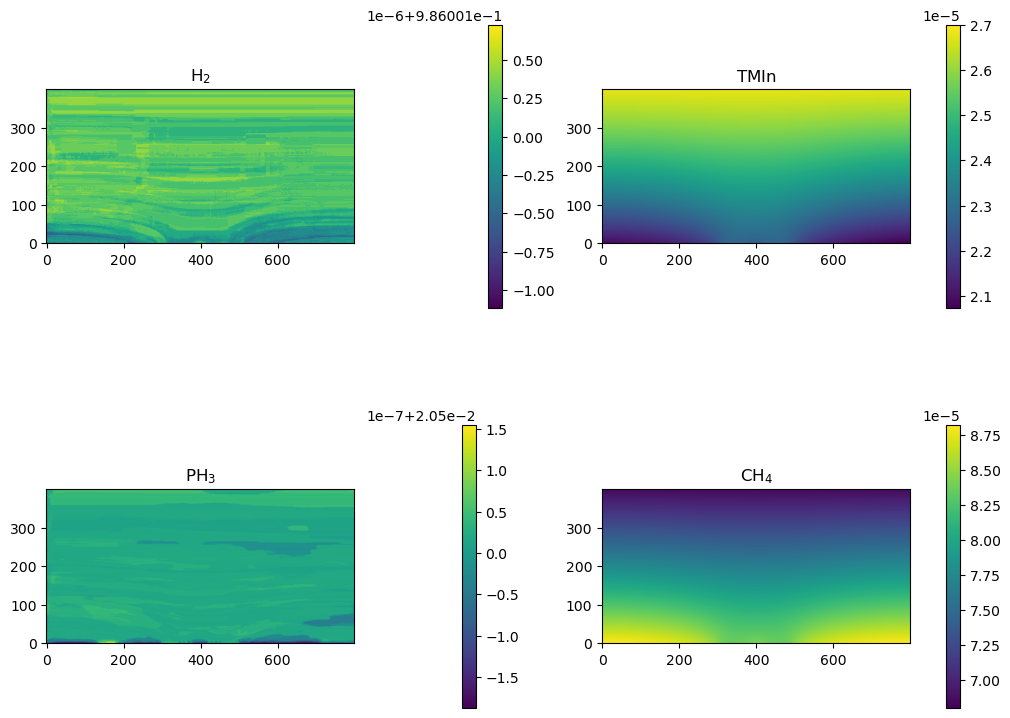

In [16]:
import matplotlib.pyplot as plt

titles = [r"$\mathrm{H_2}$", r"$\mathrm{TMIn}$", r"$\mathrm{PH_3}$", r"$\mathrm{CH_4}$"]

fig, axes = plt.subplots(2, 2, figsize=(10, 8), constrained_layout=True)

for s, ax in enumerate(axes.ravel()[:4]):
    im = ax.imshow(rho_s[s, :, :].T, origin='lower', aspect='1')
    ax.set_title(titles[s])
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.show()


In [17]:
L_growth = 0.038 # m
n_grid = nx//2

L_grid = L_growth/n_grid
print(L_grid * 1e6, "micrometers")

94.99999999999999 micrometers


In [18]:
L_sample = 500e-6 # 500 um
n_points = L_sample/L_grid
print(round(n_points))

partial_pressure = rho_s[:, nx//2, round(n_points)]
print(partial_pressure)
print(np.sum(partial_pressure))

c_top = np.array([0.979, 0.000047, 0.0204, 1e-4])
print(partial_pressure-c_top)
print((partial_pressure-c_top)/c_top)

print("ratio = ", partial_pressure[2]/partial_pressure[1])

5
[9.8600101e-01 2.2680642e-05 2.0499973e-02 8.3940569e-05]
1.0066077
[ 7.00101471e-03 -2.43193576e-05  9.99726266e-05 -1.60594307e-05]
[ 0.00715119 -0.51743314  0.00490062 -0.16059431]
ratio =  903.8533


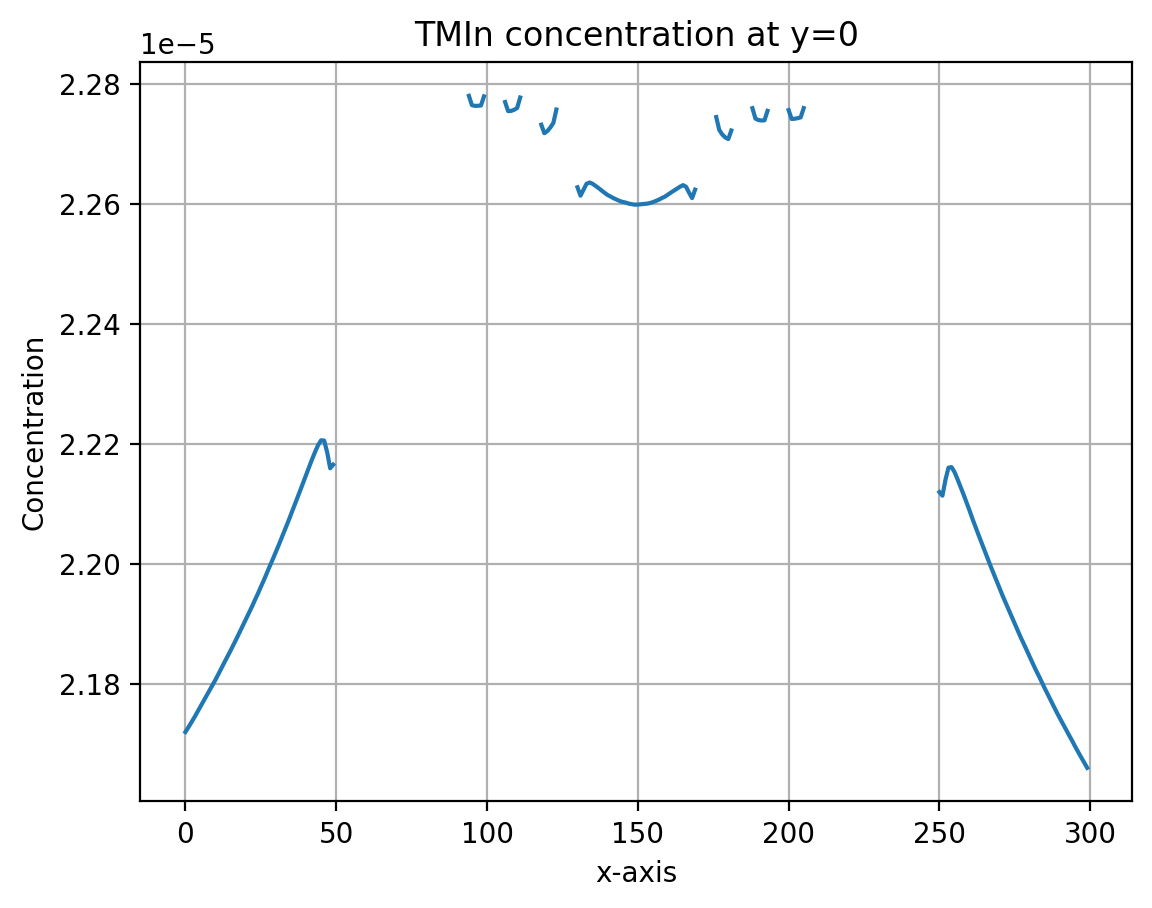

In [19]:
range_plot = slice(250,550)
c_ratio = rho_s[1,:,0]#/rho_s[1,:,0]
c_ratio[to_numpy(non_absorb_mask)==1] = np.nan
plt.figure(dpi = 200)
#plt.plot(rho_s[1, range_plot, 0])
plt.plot(c_ratio[range_plot])
plt.title("TMIn concentration at y=0")
plt.ylabel("Concentration")
plt.xlabel("x-axis")
plt.grid()
#plt.ylim(bottom=0)

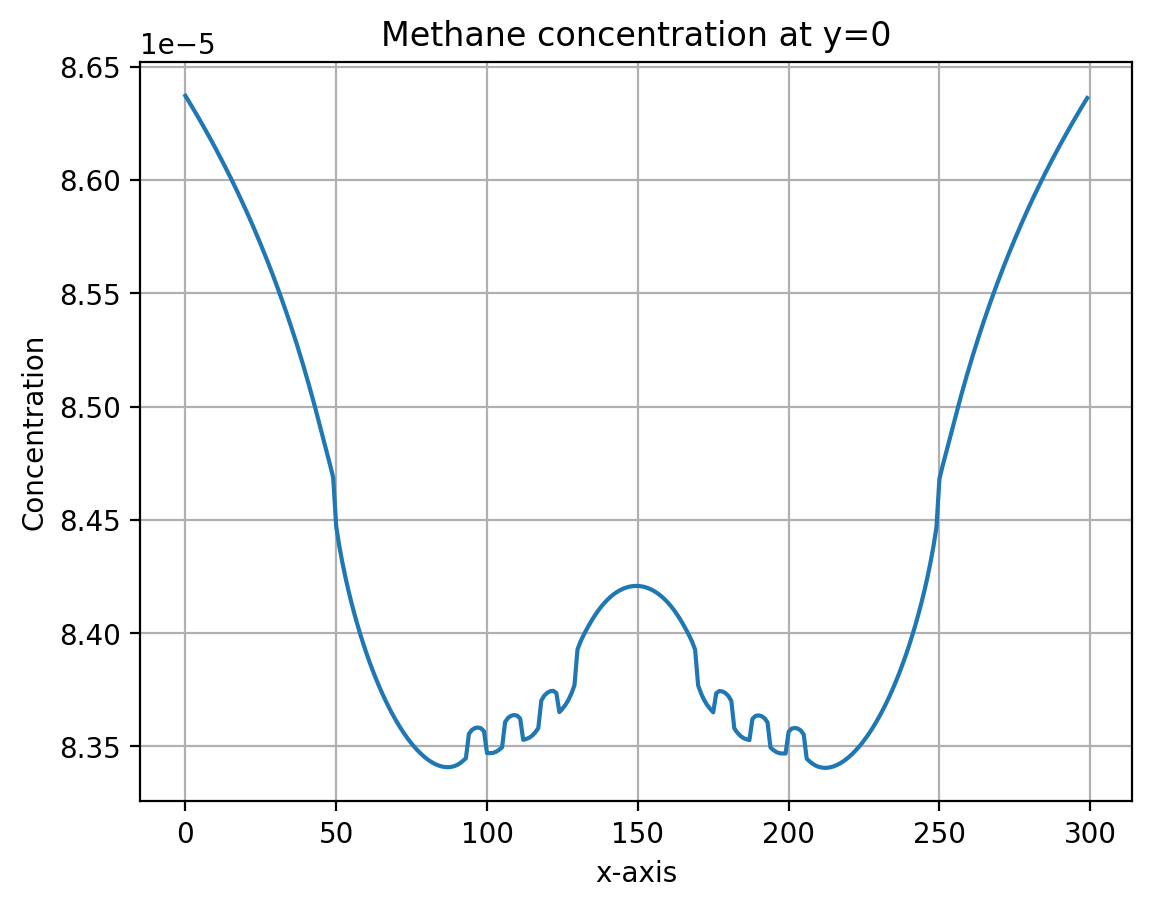

In [20]:
plt.figure(dpi = 200)
plt.plot(rho_s[3, range_plot, 0])
plt.title("Methane concentration at y=0")
plt.ylabel("Concentration")
plt.xlabel("x-axis")
plt.grid()
#plt.ylim(bottom=0)

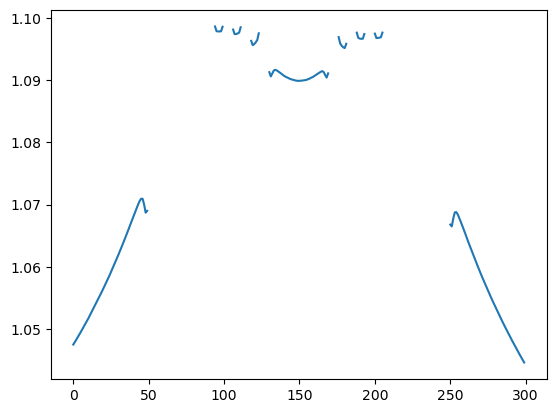

In [21]:
c_ratio = rho_s[1,:,0]/np.nanmin(rho_s[1,:,0])
c_ratio[to_numpy(non_absorb_mask)==1] = np.nan
plt.plot(c_ratio[range_plot])


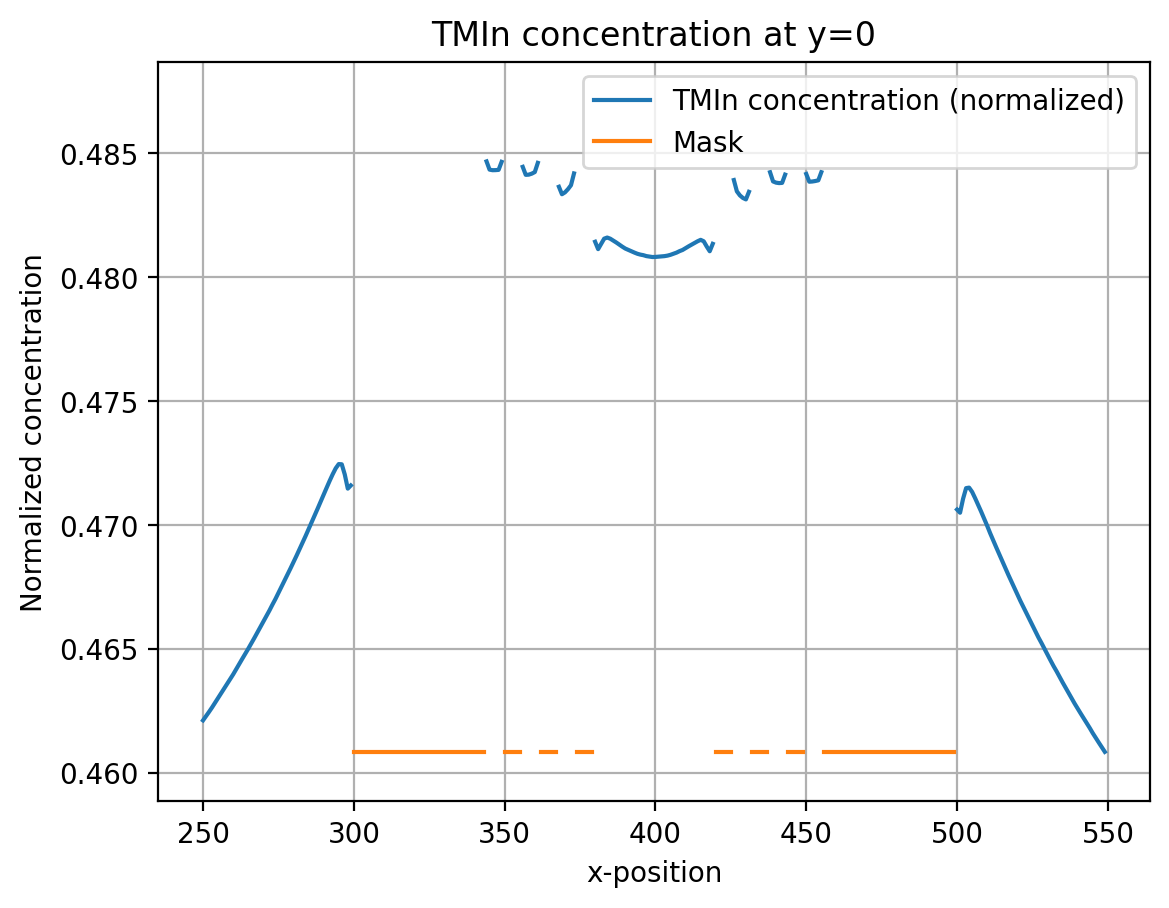

In [22]:
boundary_concentration = rho_s[1, :, 0] / c_top[1]
boundary_concentration[to_numpy(non_absorb_mask)==1] = np.nan

plt.figure(dpi = 200)
plt.plot(250+np.arange(len(boundary_concentration[range_plot])), boundary_concentration[range_plot], label = "TMIn concentration (normalized)")
plt.title("TMIn concentration at y=0")
plt.ylabel("Normalized concentration")
plt.xlabel("x-position")
plt.grid()
plt.ylim([np.nanmin(boundary_concentration[range_plot])-0.002, np.nanmax(boundary_concentration[range_plot])+0.004])

mask_slice = to_numpy(non_absorb_mask)[range_plot]
mask_slice[mask_slice==0] = np.nan
plt.plot(250+np.arange(len(boundary_concentration[range_plot])),
         mask_slice-1+np.nanmin(boundary_concentration[range_plot]),
         label = "Mask")
plt.legend(loc='upper right')

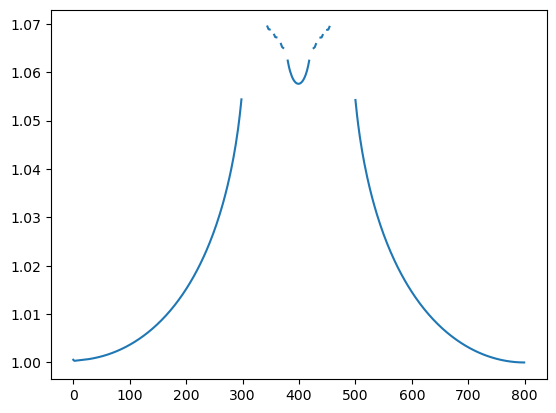

In [50]:
LBM_diffusion_profile = np.load("LBM_diffusion_profile.npy")
interp_lbm_diff = np.interp(np.arange(nx), np.arange(len(LBM_diffusion_profile))*2, LBM_diffusion_profile)
plt.plot(interp_lbm_diff)

(250.0, 550.0)

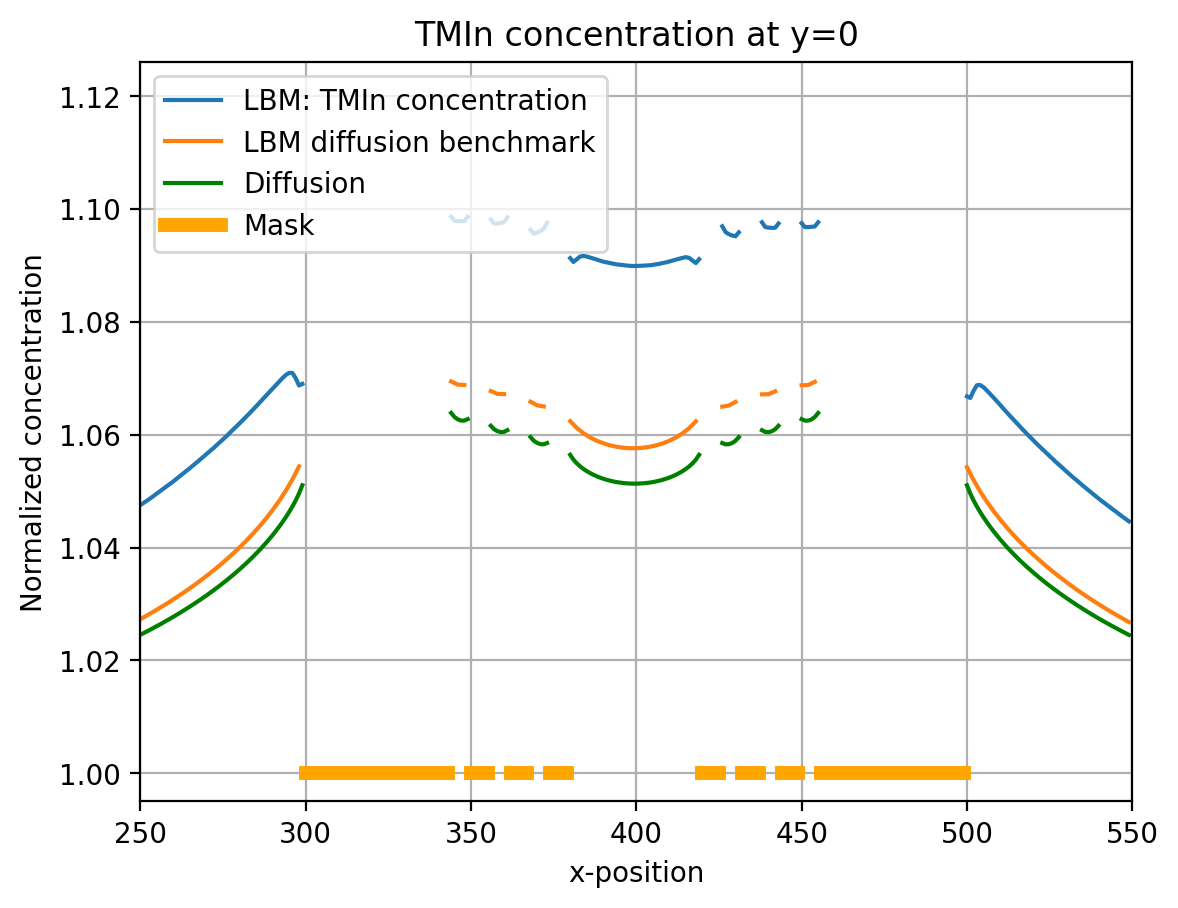

In [55]:
# LBM profile
boundary_concentration = rho_s[1, :, 0] / c_top[1]
boundary_concentration[to_numpy(non_absorb_mask)==1] = np.nan

plt.figure(dpi = 200)
plt.plot(250+np.arange(len(boundary_concentration[range_plot])), c_ratio[range_plot], label = "LBM: TMIn concentration")
plt.title("TMIn concentration at y=0")
plt.ylabel("Normalized concentration")
plt.xlabel("x-position")
plt.grid()
plt.ylim([0.995, 1.126])

# LBM_diffusion_profile
plt.plot(250+np.arange(len(boundary_concentration[range_plot])), interp_lbm_diff[range_plot], label = "LBM diffusion benchmark")

# diffusion profile
plt.plot(250+np.arange(len(boundary_concentration[range_plot])), diff_percentage[range_plot], label = "Diffusion", color = "green")

#plot mask
mask_slice = to_numpy(non_absorb_mask)[range_plot]
mask_slice[mask_slice==0] = np.nan
plt.plot(250+np.arange(len(boundary_concentration[range_plot])),
         #mask_slice-1+np.nanmin(boundary_concentration[range_plot]),
         mask_slice,
         linewidth = 5, label = "Mask", color = "orange")

plt.legend(loc='upper left')
plt.xlim([250,550])

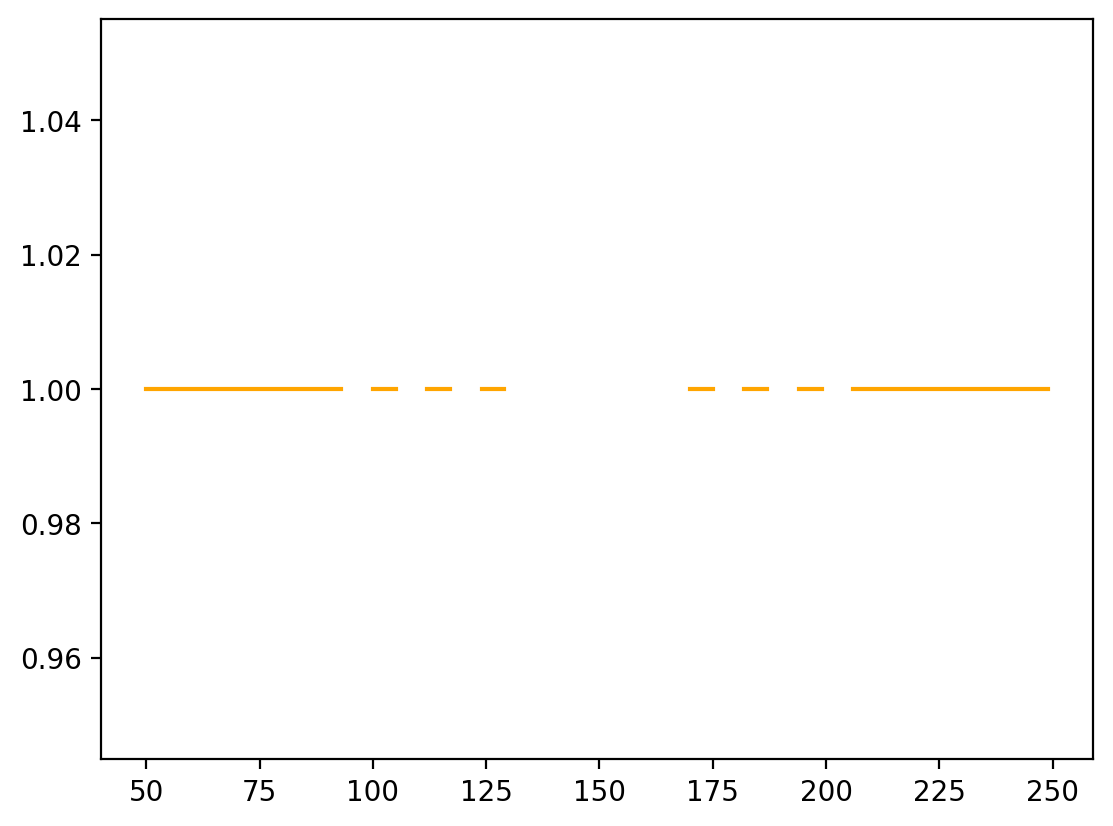

In [113]:
plt.figure(dpi = 200)
plt.plot(mask_slice, color = "orange")

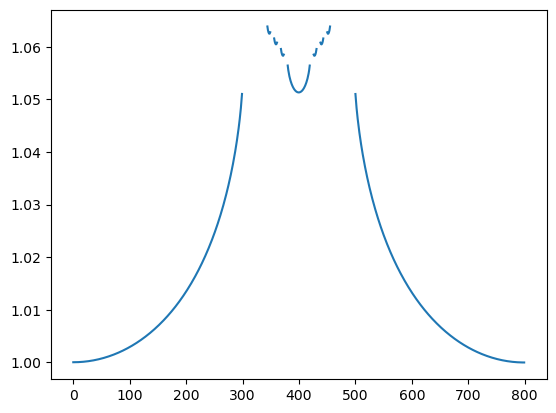

In [24]:
C_diff = np.load("diffusion_result.npy")
diff_boundary_c = C_diff[:,0]
diff_ase_c = np.nanmin(diff_boundary_c)
diff_percentage = diff_boundary_c/diff_ase_c

plt.plot(diff_percentage)